## Part 2: Methods Application — Linear Regression

**Dataset:** `dataset_grupo_22.csv` — 2000 patient profiles. **Variable to predict:** `target_regression`

### Objective
1. **Simple Linear Regression:** fit a model with a single feature, test several features and choose the most
   suitable one.
2. **Multiple Linear Regression:** fit a model with several clinical features, try combinations and
   determine the best group.
3. **Comparison and discussion:** evaluate the two models with R², MAE and RMSE and discuss the results.

### Starting point: what the EDA has already told us
The exploratory analysis (`01_EDA.ipynb`) left three findings that guide everything that follows:

| EDA result | Consequence for the regression |
|---|---|
| The highest correlation with the target is that of `bmi` (r ≈ 0.07). All the others are even closer to 0. | In simple regression, R² = r². Even the best feature will explain **less than 1%** of the variance. **We do not expect a good model.** |
| The features are practically independent of one another, except for continuous/discretized pairs (`age`/`age_level`, `bmi`/`bmi_level`). | Combining features may accumulate small contributions, but it only makes sense to use **one version** of each variable. |
| `calcium_baseline` is constant; `systolic_index` and `age_normalized` are copies of other features; `ldl_alternative` holds the values of `ldl` shuffled between patients (it does not belong to the patient on that row). | They are removed before modelling. |

The goal of this part is therefore to **test rigorously** whether any feature or combination can predict the
target better than a model with no information, and to **explain why** some combinations work better than
others.

### Theoretical background
- Simple regression: $Y = \beta_0 + \beta_1 X + \varepsilon$. Multiple: $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$.
- Coefficients estimated by **least squares**, minimizing $RSS = \sum (y_i - \hat y_i)^2$.
- $R^2 = 1 - RSS/TSS$: proportion of the variance explained. *t* tests (each coefficient) and *F* test (the whole
  model) assess statistical significance.
- Problems to watch for: non-linearity, non-constant variance, *outliers*, **collinearity**.

### Method decisions
| Decision | Why |
|---|---|
| *Holdout* 70% train / 30% test, seed 22 | Allowed by the assignment; same proportion as the Boston Housing example; seed fixed by the project rules. |
| Choices made **on the training set only**, with 5-fold cross-validation | Choosing the best combination by looking at the test set would make the test error optimistic. |
| Test set used **only once** (section 4) | An honest estimate of the error on new patients. |
| Always compared against a ***baseline*** (predicting the mean) | An R² or an RMSE only mean something compared with "using no feature at all". |
| `target_class` is **not** a predictor | It is the other target of the assignment (project rule). |

## 1. Data preparation

### 1.1 Loading the data and setting up the environment

We load the libraries and the original dataset. The CSV file is **never modified**: every transformation is done
on an in-memory copy.

We fix the random seed at **22**. This way the train/test split and the cross-validation always give the same
results, and any member of the group can reproduce the notebook.

We use two regression libraries, as in the lectures:
- **scikit-learn** (`LinearRegression`), to train, predict and validate;
- **statsmodels** (`OLS`), to obtain the statistical table (standard errors, *t* and *F* tests, p-values)

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next(p for p in candidates if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dataset shape:', raw.shape)
raw[['age', 'bmi', 'HbA1c_level', 'smoking', 'employment_status', 'target_regression']].head()

Dataset shape: (2000, 35)


,age,bmi,HbA1c_level,smoking,employment_status,target_regression
0,87,23.6000,7.0800,Never,Retired,90.0000
1,56,36.7000,8.2000,Never,Unemployed,220.0000
2,67,39.8000,6.8618,Current,Employed,172.0000
3,39,21.4000,6.9000,Current,Employed,92.0000
4,74,23.0000,7.0800,Never,Retired,152.0000


**Conclusions:** the dataset has **2000 rows and 35 columns**, as in the EDA. There are numeric features (`age`,
`bmi`, `HbA1c_level`), text categorical ones (`smoking`, `employment_status`) and the target, which ranges
between values like 90 and 220 in the first rows.

### 1.2 Removing features and encoding the categorical ones

**What we do and why:**

1. **We remove the 4 features that the EDA (`01_EDA`) decided to remove:**
   - `calcium_baseline`: it is constant (9.42 on every row). A variable that does not vary cannot explain the
     variation of the target. Besides, in a regression it would be collinear with the intercept β₀.
   - `systolic_index`: it is an exact copy of `systolic_bp`. With both in the model, the matrix $X^TX$ becomes
     singular and $\hat\beta = (X^TX)^{-1}X^Ty$ no longer has a unique solution.
   - `age_normalized`: it is a rescaling of `age`, with the same problem;
   - `ldl_alternative`: it holds the same values as `ldl`, but shuffled between patients (it matches on only 18 of
     2000 rows). The value does not belong to the patient on that row, so it is noise and must not enter the model.

2. **We convert the categorical variables into numbers**, because linear regression only works with numeric
   values:
   - **ordinal** ones (they have a natural order, e.g. Low < Medium < High) → codes 0, 1, 2…, which preserve the
     order in a single column;
   - **binary** ones (Yes/No, Male/Female) → 0/1;
   - **nominal** ones with no order (`employment_status`) → *one-hot* with `drop_first=True`, just like
     `pd.get_dummies` in the PL2 exercise (Insurance). If we did not drop one column, the *dummies* would always
     sum to 1 and would be collinear with the intercept (the "dummy variable trap").

3. **We take both targets out of the predictor matrix.** `target_class` is the other outcome to predict in the
   assignment; using it to predict `target_regression` would be using one outcome to predict another.

The "uninformative" features from the EDA are **not** removed here. The point of this part is precisely to test
them and let the results confirm (or not) what the EDA suggested.

In [2]:
TARGET = 'target_regression'
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']

ORDINAL = {
    'age_level':         ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level':         ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking':           ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level':      ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level':   ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_class'])
y = data[TARGET]
assert X.isna().sum().sum() == 0, 'the encoding produced missing values'
FEATURES = list(X.columns)
CONTINUOUS = [c for c in FEATURES if c in raw.columns and pd.api.types.is_numeric_dtype(raw[c])]
print(f'{len(FEATURES)} candidate features ({len(CONTINUOUS)} continuous numeric):')
print(FEATURES)

30 candidate features (17 continuous numeric):
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'plasma_value', 'employment_status_Retired', 'employment_status_Unemployed']


**Conclusions:** **30 candidate features** remain (35 columns − 4 removed − 2 targets), of which 17 are
continuous numeric and 13 come from encoded categorical variables. `employment_status` gave rise to 2 columns
(`Retired` and `Unemployed`; `Employed` is the reference category, represented by 0 in both). The encoding
produced no missing values.

### 1.3 Train/test split (*holdout*)

The assignment allows evaluation with the *holdout* method: separating the data into train and test.
- The model **learns** the β coefficients using the **training** set only.
- The **test** set simulates "new patients" and measures the ability to **generalize**.

We use **70% / 30%**, leaving 1400 records for training, which is enough to estimate a handful of coefficients,
and 600 for testing, which gives a reasonable estimate of the error.

**Important rule:** every choice (which feature, which combination) is made **with the training set only**. The
test set is used once, at the end (section 4). If we chose the combination that gives the smallest error on the
test set, the test set itself would become part of the choice, and the reported error would be optimistic.

We also check whether the target has a similar distribution in the two sets. If it did not, the test set would
not be representative.

train: (1400, 30) | test: (600, 30)
          count     mean     std     min      25%      50%      75%      max
train 1400.0000 136.9237 41.3707 70.0000 103.0000 135.0000 167.0000 300.0000
test   600.0000 133.8167 40.9325 70.0000  97.0000 131.0000 164.0000 300.0000

Kolmogorov-Smirnov test (same distribution?): p = 0.288


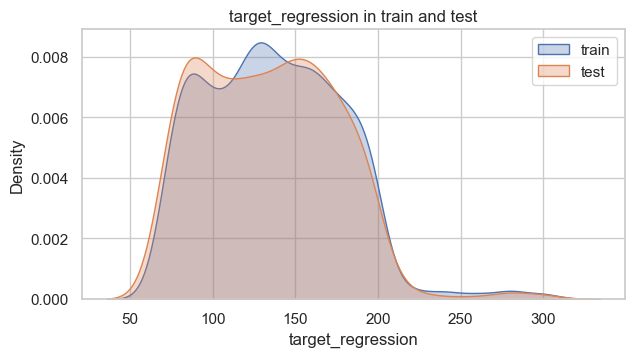

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)
print(pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()}).T)
print(f'\nKolmogorov-Smirnov test (same distribution?): p = {stats.ks_2samp(y_train, y_test).pvalue:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(y_train, ax=ax, label='train', fill=True, alpha=.3)
sns.kdeplot(y_test, ax=ax, label='test', fill=True, alpha=.3)
ax.set_title('target_regression in train and test'); ax.legend(); plt.show()

**Conclusions:** the training set has **1400** records and the test set **600**. The target distributions are
similar in the two sets:
- means of 136.9 and 133.8, standard deviations of 41.4 and 40.9, and the same range (70–300);
- the Kolmogorov-Smirnov test finds no difference (p = 0.288).

**Justification:** the random split produced a representative test set. Any differences we find between train
and test will come from the model, not from an unbalanced split.

### 1.4 Evaluation metrics, cross-validation and reference model (*baseline*)


| Metric | Formula | What it says |
|---|---|---|
| **R²** | $1 - RSS/TSS$ | Proportion of the target's variance explained by the model. 1 = perfect; **0 = as good as always predicting the mean**; negative = worse than the mean. |
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | Mean absolute error, in the units of the target. Easy to interpret and not very sensitive to isolated large errors. |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | Root mean squared error, also in the units of the target. It penalizes large errors more, because it squares them. |

**Why 5-fold cross-validation inside the training set?** To choose between features/combinations we need to
measure the error on data the model has not seen, but without touching the test set. Cross-validation splits the
training set into 5 parts: it trains on 4, evaluates on the 5th, and repeats 5 times. The average of the 5
evaluations is more stable than a single split.

**Why a *baseline*?** A model with no feature always predicts the training mean. An R² or an RMSE only mean
something compared with this: **if a model does not err less than the mean, the features add no information.** It
is the regression equivalent of a classifier that always predicts the majority class.

Standardization (`StandardScaler`) does not change the predictions of a linear regression, only the scale of the
coefficients. We include it so that the coefficients are comparable with one another and to prepare for Part 4
(Ridge/Lasso), where it is mandatory.

In [ ]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

def fit_linear(X_tr, y_tr, degree=1, log_target=False):
    poly = PolynomialFeatures(degree, include_bias=False) if degree > 1 else None
    A = poly.fit_transform(X_tr) if poly is not None else np.asarray(X_tr, dtype=float)
    scaler = StandardScaler().fit(A)
    model = LinearRegression().fit(scaler.transform(A), np.log1p(y_tr) if log_target else y_tr)

    def predict(X_new):
        B = poly.transform(X_new) if poly is not None else np.asarray(X_new, dtype=float)
        p = model.predict(scaler.transform(B))
        return np.expm1(p) if log_target else p
    return predict

def predict_mean(y_tr):
    mean = float(y_tr.mean())
    return lambda X_new: np.full(len(X_new), mean)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}

def cv_scores(cols, degree=1, log_target=False, baseline=False, Xd=None, yd=None):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    r2_train, r2_val, mae_val, rmse_val = [], [], [], []
    for train_idx, valid_idx in CV.split(Xd):
        X_a, X_b = Xd[cols].iloc[train_idx], Xd[cols].iloc[valid_idx]
        y_a, y_b = yd.iloc[train_idx], yd.iloc[valid_idx]
        predict = predict_mean(y_a) if baseline else fit_linear(X_a, y_a, degree, log_target)
        r2_train.append(r2_score(y_a, predict(X_a)))
        p = predict(X_b)
        r2_val.append(r2_score(y_b, p))
        mae_val.append(mean_absolute_error(y_b, p))
        rmse_val.append(np.sqrt(mean_squared_error(y_b, p)))
    return {'train_r2': float(np.mean(r2_train)), 'cv_r2': float(np.mean(r2_val)),
            'cv_r2_std': float(np.std(r2_val)), 'cv_mae': float(np.mean(mae_val)),
            'cv_rmse': float(np.mean(rmse_val))}

baseline_cv = cv_scores(FEATURES, baseline=True)
print(f'Standard deviation of the target in the training set: {y_train.std():.3f}')
pd.Series(baseline_cv, name='baseline (mean)').to_frame().T

Standard deviation of the target in the training set: 41.371


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
baseline (mean),0.0000,-0.0059,0.0037,33.9541,41.3848


**Conclusions:** the *baseline* errs, on average, by **34.0 units (MAE)**, with an RMSE of **41.4**. This RMSE is
practically equal to the standard deviation of the target (41.37), which is expected: always predicting the mean
produces an error equal to the natural dispersion of the data.

**This is the value to beat.** A feature is only useful if it makes the RMSE drop clearly below 41.4.

**A note on the baseline R²:** in cross-validation it is not exactly 0, but −0.006. In each fold the mean is
computed on that fold's training data and evaluated on different data, where the true mean is slightly different.
That is why, throughout the notebook, **we compare models against the baseline (−0.006) and not against zero.**

## 2. Simple Linear Regression

$$\hat y = \hat\beta_0 + \hat\beta_1 x$$

A single feature tries to explain the target. The coefficients are chosen by **least squares**, that is, so as to
minimize $RSS = \sum (y_i - \hat y_i)^2$.

**Strategy:**
1. Work out, from the EDA, **what the best possible R² is** (2.1).
2. Test **every** feature, one at a time (2.2).
3. Compare with a **random feature**, to find out whether the best ones differ from noise (2.3).
4. Analyse the chosen model in detail, with plots and residuals (2.4–2.6).
5. Check whether a **non-linear** relationship (polynomial) would be better (2.7).

### 2.1 What to expect? The limit the EDA already gives us

In simple linear regression there is a direct relationship between the Pearson correlation and the R²:

$$R^2_{\text{train}} = r^2$$

In other words, **the correlation computed in the EDA tells us, before training any model, what the maximum R²**
each feature can reach on the training set is. In the EDA, the highest correlation with the target was that of
`bmi` (r ≈ 0.07). We compute r and r² for every feature on the training set.

In [5]:
r_train = X_train.corrwith(y_train)
expected = pd.DataFrame({'r (train)': r_train, 'r2 = max expected R2': r_train ** 2,
                         '% variance explained': r_train ** 2 * 100})
expected.sort_values('r2 = max expected R2', ascending=False).head(10)

,r (train),r2 = max expected R2,% variance explained
bmi,0.0741,0.0055,0.5489
age,0.0699,0.0049,0.4879
age_level,0.0612,0.0037,0.3740
smoking,-0.0603,0.0036,0.3639
salt_intake,-0.0568,0.0032,0.3228
triglycerides,0.0530,0.0028,0.2814
bmi_level,0.0504,0.0025,0.2541
physical_activity,0.0496,0.0025,0.2464
HbA1c_level,0.0437,0.0019,0.1913
high_ldl_cholesterol,0.0396,0.0016,0.1572


**Conclusions:** before training any model, we already know the **best possible training R²** for a simple
regression:
- **`bmi`: r = 0.074 → maximum R² = 0.0055**, that is, **0.55%** of the target's variance;
- `age` comes next with 0.49%, then `age_level` (0.37%) and `smoking` (0.36%).

**Justification:** with a single feature, the least-squares line explains exactly r² of the variance. Since no
feature has |r| above 0.075, **no simple regression can explain more than ~0.5% of the variance**, not even on
the training set. This result numerically confirms what the EDA indicated: even the best feature will not give a
good model.

### 2.2 Testing every feature, one at a time

For each of the 30 features we fit a simple regression and record:
- the **training R²** (it should match the r² of the previous table);
- **β₁ and its p-value** (*t* test for $H_0: \beta_1 = 0$). A p-value < 0.05 indicates that the relationship is
  statistically significant;
- **R², MAE and RMSE in cross-validation**: this is the **selection criterion**, because it measures performance
  on data that was not used to estimate the coefficients.

The table is sorted by CV RMSE (lower = better). We show the *baseline* for comparison.

In [6]:
rows = []
for f in FEATURES:
    ols = sm.OLS(y_train, sm.add_constant(X_train[[f]])).fit()
    cv = cv_scores([f])
    rows.append({'feature': f, 'R2_train': ols.rsquared, 'beta1': ols.params[f], 'p_value': ols.pvalues[f],
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse'],
                 'better than baseline?': cv['cv_rmse'] < baseline_cv['cv_rmse']})
simple = pd.DataFrame(rows).set_index('feature').sort_values('cv_rmse')
print('Baseline: CV R2 = {cv_r2:.4f} | CV MAE = {cv_mae:.3f} | CV RMSE = {cv_rmse:.3f}'.format(**baseline_cv))
print(f"Features with p < 0.05: {(simple['p_value'] < 0.05).sum()} of {len(simple)}")
print(f"Features with CV RMSE below the baseline: {simple['better than baseline?'].sum()} of {len(simple)}")
simple

Baseline: CV R2 = -0.0059 | CV MAE = 33.954 | CV RMSE = 41.385
Features with p < 0.05: 6 of 30
Features with CV RMSE below the baseline: 11 of 30


,R2_train,beta1,p_value,cv_r2,cv_mae,cv_rmse,better than baseline?
feature,,,,,,,
bmi,0.0055,0.4254,0.0055,-0.0024,33.9732,41.3094,True
age,0.0049,0.1412,0.0089,-0.0028,33.8315,41.3234,True
age_level,0.0037,2.6719,0.0221,-0.0036,33.8664,41.3393,True
bmi_level,0.0025,1.9577,0.0594,-0.0038,33.9739,41.3410,True
HbA1c_level,0.0019,3.1327,0.1019,-0.0043,34.0091,41.3526,True
smoking,0.0036,-3.0273,0.0240,-0.0044,33.9326,41.3553,True
salt_intake,0.0032,-0.6723,0.0335,-0.0053,33.8729,41.3683,True
blood_pressure,0.0012,0.2771,0.1946,-0.0051,33.9363,41.3685,True
physical_activity,0.0025,2.5201,0.0634,-0.0054,33.9736,41.3725,True


**Conclusions:**
- The training R² of each feature **matches the r²** of the previous table (`bmi`: 0.0055), which confirms the
  relationship R² = r².
- **`bmi` is the best feature** on every criterion: highest training R², lowest CV RMSE (41.309) and the lowest
  p-value (0.0055). It is followed by `age` (RMSE 41.323) and `age_level` (41.339).
- **6 of the 30 features have a significant β₁** (p < 0.05): `bmi`, `age`, `age_level`, `smoking`, `salt_intake`
  and `triglycerides`.
- Only **11 of the 30** have a CV RMSE below the baseline, and **none has a positive CV R²** (the best is
  −0.0024, for `bmi`).

**Justification — why do these features come out on top?** They are the ones with the highest |r| with the target
(section 2.1). `bmi` and `age` always appear at the top: in the EDA's correlation table, in the p-values and now
in the validation error.

**Why is the gain so small?** `bmi` lowers the RMSE from 41.385 (baseline) to 41.309: **less than 0.1 units**, on
a target with a standard deviation of 41. This happens because `bmi` explains only 0.55% of the variance: the
remaining 99.45% stay unexplained.

**Significance ≠ predictive power.** The β₁ of `bmi` is significant (p = 0.006) because, with 1400 records, even
minuscule effects can be told apart from zero. The p-value says the effect probably **exists**; it does not say
it is **large** or useful for prediction.

### 2.3 Are the best features different from noise?

When the relationship between X and Y is **random**, the R² stays close to 0 and the coefficient is not
significant. We use that idea as a **control**: we create 500 features of **pure noise** (random numbers with no
relation whatsoever to the target), fit a simple regression with each one and see what training R² we obtain
**purely by chance**.

If the R² of `bmi` ends up clearly above what noise can achieve, the relationship is real (however weak). If it
falls in the middle of the noise distribution, `bmi` is no better than a random number.

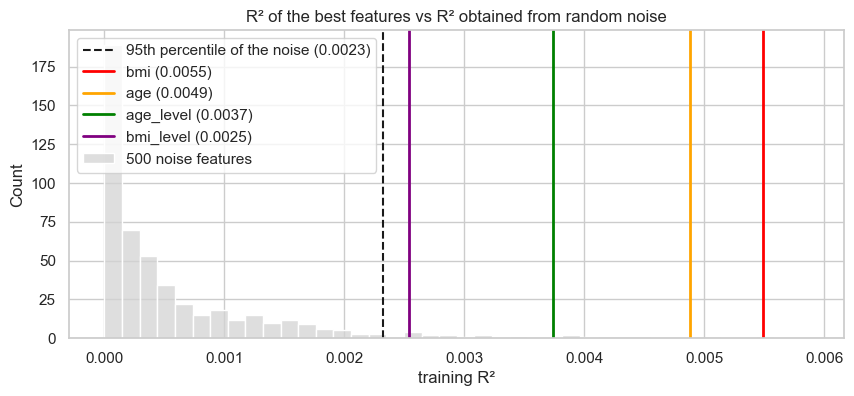

Mean R2 of the noise: 0.0006 | 95th percentile: 0.0023
Features above the 95th percentile of the noise (8): ['bmi', 'age', 'age_level', 'bmi_level', 'smoking', 'salt_intake', 'physical_activity', 'triglycerides']


In [7]:
rng = np.random.default_rng(SEED)
noise_r2 = np.array([sm.OLS(y_train, sm.add_constant(rng.normal(size=len(y_train)))).fit().rsquared
                     for _ in range(500)])
p95 = np.percentile(noise_r2, 95)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(noise_r2, bins=40, ax=ax, color='lightgrey', label='500 noise features')
ax.axvline(p95, color='k', ls='--', label=f'95th percentile of the noise ({p95:.4f})')
for f, c in zip(simple.index[:4], ['red', 'orange', 'green', 'purple']):
    ax.axvline(simple.loc[f, 'R2_train'], color=c, lw=2, label=f'{f} ({simple.loc[f, "R2_train"]:.4f})')
ax.set_xlabel('training R²'); ax.set_title('R² of the best features vs R² obtained from random noise'); ax.legend()
plt.show()

real = (simple['R2_train'] > p95)
print(f'Mean R2 of the noise: {noise_r2.mean():.4f} | 95th percentile: {p95:.4f}')
print(f'Features above the 95th percentile of the noise ({real.sum()}):', list(simple.index[real]))

**Conclusions:** the 500 noise features reach, purely by chance, a mean R² of **0.0006**, and 5% of them get past
**0.0023**. **8 features end up above this threshold**: `bmi` (0.0055), `age` (0.0049), `age_level`, `bmi_level`,
`smoking`, `salt_intake`, `physical_activity` and `triglycerides`.

**Justification:** `bmi` explains about **9 times** more variance than a typical random feature, and more than
twice the 95th percentile of the noise. **The relationship is real**, not an accident of the sample. At the same
time, the chart shows that all the features live on the same minuscule scale as the noise (0 to 0.006). The
relationship exists, but it is too weak to be of practical use.

The remaining 22 features fall inside the noise distribution: **they cannot be told apart from random numbers**,
which matches the "uninformative" features identified in the EDA.

### 2.4 Chosen simple model: statistical analysis (OLS)

We choose the feature with the **lowest cross-validated RMSE** (table 2.2). We analyse it with `statsmodels`, to
obtain:
- the coefficients $\hat\beta_0$ and $\hat\beta_1$ and their **interpretation**;
- the **standard error** and the **95% confidence interval** of $\hat\beta_1$;
- the ***t* test** and the p-value.

We also compute predictions for specific patients, to give practical meaning to the coefficient.

In [8]:
BEST_SIMPLE = simple.index[0]
ols_simple = sm.OLS(y_train, sm.add_constant(X_train[[BEST_SIMPLE]])).fit()
print(f'Chosen feature: {BEST_SIMPLE}\n')
print(ols_simple.summary().tables[1])
b0, b1 = ols_simple.params
print(f'\nEquation: target_regression = {b0:.3f} + {b1:.3f} x {BEST_SIMPLE}')
print(f'Training R2 = {ols_simple.rsquared:.4f}\n')
for v in (18.5, 25, 30, 40):
    print(f'  {BEST_SIMPLE} = {v:>4}  ->  prediction = {b0 + b1 * v:.1f}')
print(f'\nActual range of the target: {y_train.min():.0f} to {y_train.max():.0f} (standard deviation {y_train.std():.1f})')

Chosen feature: bmi

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.0606      4.411     28.353      0.000     116.408     133.713
bmi            0.4254      0.153      2.778      0.006       0.125       0.726

Equation: target_regression = 125.061 + 0.425 x bmi
Training R2 = 0.0055

  bmi = 18.5  ->  prediction = 132.9
  bmi =   25  ->  prediction = 135.7
  bmi =   30  ->  prediction = 137.8
  bmi =   40  ->  prediction = 142.1

Actual range of the target: 70 to 300 (standard deviation 41.4)


**Conclusions — chosen simple model: `bmi`.**

$$\widehat{target} = 125.06 + 0.425 \times bmi$$

- **Interpretation of β₁:** for each extra unit of BMI, the target increases on average by **0.43 units**. The 95%
  confidence interval is [0.125, 0.726], which does not include 0, and the *t* test gives p = 0.006.
- **Interpretation of β₀:** 125.06 would be the predicted value for BMI = 0. It has no clinical meaning (nobody
  has BMI 0); it only serves to position the line.
- **Prediction examples:** a lean patient (BMI 18.5) gets a prediction of 132.9 and a patient with severe obesity
  (BMI 40) one of 142.1. **A difference of 21.5 BMI units changes the prediction by only 9 units**, on a target
  that ranges from 70 to 300 (standard deviation 41.4).

**Justification for the choice:** `bmi` is the best on every criterion: training R² (0.0055), CV RMSE (41.309),
p-value (0.006), and the only one of these with a relationship clearly above the noise (2.3). It is also a
continuous measurement, more informative than its categorical version `bmi_level`. The choice is consistent with
the EDA, where `bmi` was already the feature most correlated with the target.

### 2.5 Visualization: actual vs predicted values

We use three charts on the training set:
1. **Scatter plot with the fitted line**: actual values (points) and the line $\hat y = \hat\beta_0 + \hat\beta_1 x$;
2. **Distribution of actual vs predicted values**: a good model produces predictions with a distribution similar
   to that of the actual values;
3. **Prediction error** (residual) of each record.

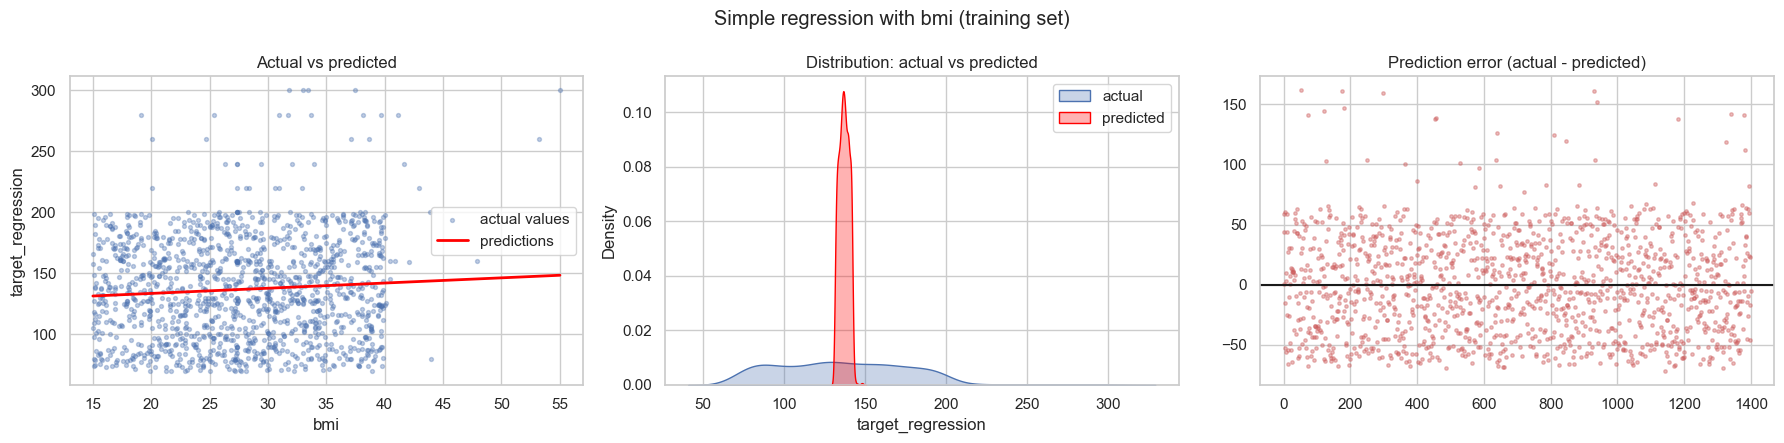

Predictions: min 131.4, max 148.5, standard deviation 3.07  |  actual values: standard deviation 41.37


In [9]:
pred_simple_train = ols_simple.fittedvalues

def plot_real_vs_pred(x, y_real, y_pred, xlabel, title, line=True):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].scatter(x, y_real, s=8, alpha=.35, label='actual values')
    if line:
        order = np.argsort(np.asarray(x))
        axes[0].plot(np.asarray(x)[order], np.asarray(y_pred)[order], color='red', lw=2, label='predictions')
    else:
        axes[0].scatter(x, y_pred, s=8, alpha=.5, color='red', label='predictions')
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel('target_regression'); axes[0].legend()
    axes[0].set_title('Actual vs predicted')
    sns.kdeplot(y_real, ax=axes[1], fill=True, alpha=.3, label='actual')
    sns.kdeplot(y_pred, ax=axes[1], fill=True, alpha=.3, color='red', label='predicted')
    axes[1].set_title('Distribution: actual vs predicted'); axes[1].legend()
    axes[2].scatter(range(len(y_real)), np.asarray(y_real) - np.asarray(y_pred), s=6, alpha=.4, color='indianred')
    axes[2].axhline(0, color='k'); axes[2].set_title('Prediction error (actual - predicted)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_real_vs_pred(X_train[BEST_SIMPLE], y_train, pred_simple_train, BEST_SIMPLE,
                  f'Simple regression with {BEST_SIMPLE} (training set)')
print(f'Predictions: min {pred_simple_train.min():.1f}, max {pred_simple_train.max():.1f}, '
      f'standard deviation {pred_simple_train.std():.2f}  |  actual values: standard deviation {y_train.std():.2f}')

**Conclusions:**
1. **Actual vs predicted:** the line is almost **horizontal**. The actual points are spread across the whole
   70–200 band, for any value of BMI. Knowing a patient's BMI hardly helps in guessing their target.
2. **Distribution:** the contrast is the most revealing result. The actual values spread from 70 to 300 (standard
   deviation **41.4**); the predictions concentrate in a narrow peak between 131 and 149 (standard deviation
   **3.1**). **The model predicts practically the same value (~137) for every patient.**
3. **Prediction error:** the errors run from about −65 to +160 and show no pattern across the records.

**Justification:** this is exactly what an R² of 0.0055 means in practice. When a feature barely explains the
target, the best least-squares strategy is to predict a value close to the mean for everyone. It is the same
phenomenon as in classification: a model without good features tends to always predict the majority class; here
it tends to always predict the mean.

### 2.6 Residual diagnostics

Problems to check in a linear regression - using the residuals $e_i = y_i - \hat y_i$:
- **Residuals vs fitted values**: a curve would indicate **non-linearity**; a "funnel" would indicate
  **non-constant variance** of the errors;
- **Q-Q plot**: compares the residuals with a normal distribution. Normality of the errors is an assumption of
  the *t* and *F* tests.

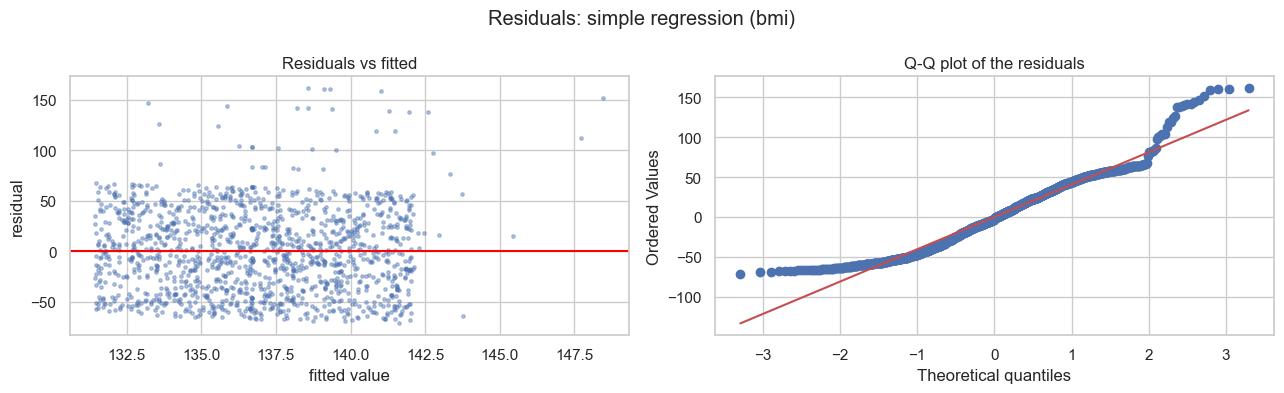

mean of the residuals = -0.000 | skew = 0.50
Records with the target at the lower bound (70): 10 | at the upper bound (300): 5


In [10]:
def residual_plots(fitted, resid, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(fitted, resid, s=6, alpha=.4); axes[0].axhline(0, color='red')
    axes[0].set_xlabel('fitted value'); axes[0].set_ylabel('residual'); axes[0].set_title('Residuals vs fitted')
    stats.probplot(resid, plot=axes[1]); axes[1].set_title('Q-Q plot of the residuals')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(f'mean of the residuals = {np.mean(resid):.3f} | skew = {stats.skew(resid):.2f}')

residual_plots(ols_simple.fittedvalues, ols_simple.resid, f'Residuals: simple regression ({BEST_SIMPLE})')
print(f'Records with the target at the lower bound (70): {(y_train == 70).sum()} | at the upper bound (300): {(y_train == 300).sum()}')

**Conclusions:**
- **Residuals vs fitted:** the cloud is a horizontal band, with no curvature and no "funnel" shape. **There are no
  signs of non-linearity or of non-constant variance.**
- **Q-Q plot:** the residuals depart from the normal in the tails and show **positive skew** (skew = 0.50). This
  is due to the few very high target values (up to 300), which generate large positive residuals. With n = 1400,
  the *t* and *F* tests remain approximately valid (central limit theorem).
- There are 10 records at the minimum value (70) and 5 at the maximum (300) of the training set. The EDA had
  flagged this accumulation at the extremes as possible truncation, but it affects few records.

**Justification:** the residuals do not indicate that the model has the **wrong shape**. They indicate that the
feature **has no information**. Changing the shape of the model (for instance, using a curve) should not solve
the problem; that is what we test next.

### 2.7 Would a non-linear relationship be better?

A straight line may be too simple if the relationship is curved. By adding polynomial terms:
$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots$. It is still **linear** regression in the coefficients.

We test degrees 1 to 5 with the chosen feature. A higher degree **always** increases the training R², because the
model becomes more flexible. That is why the choice has to be made by **cross-validation**.

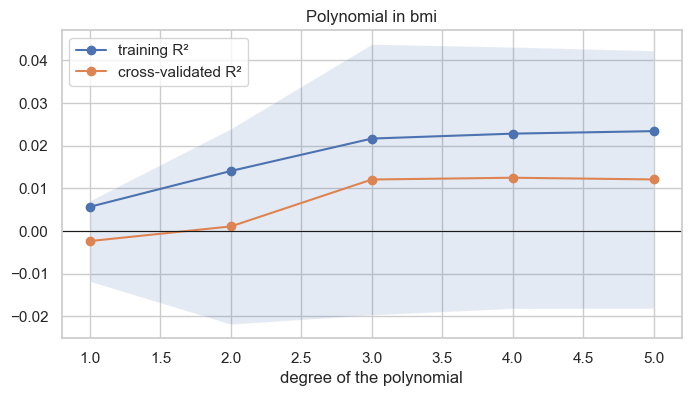

,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
degree,,,,,
1,0.0057,-0.0024,0.0095,33.9732,41.3094
2,0.0141,0.0011,0.0229,33.9041,41.2289
3,0.0216,0.0121,0.0317,33.7601,40.9945
4,0.0228,0.0125,0.0306,33.7529,40.9871
5,0.0234,0.0121,0.0302,33.7660,40.9960


In [11]:
poly = pd.DataFrame({d: cv_scores([BEST_SIMPLE], degree=d) for d in range(1, 6)}).T
poly.index.name = 'degree'

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poly.index, poly['train_r2'], marker='o', label='training R²')
ax.plot(poly.index, poly['cv_r2'], marker='o', label='cross-validated R²')
ax.fill_between(poly.index, poly['cv_r2'] - poly['cv_r2_std'], poly['cv_r2'] + poly['cv_r2_std'], alpha=.15)
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('degree of the polynomial'); ax.set_title(f'Polynomial in {BEST_SIMPLE}')
ax.legend(); plt.show()
poly

**Conclusions:**
- The **training R² always rises** with the degree (0.0057 → 0.0234), as expected: a more flexible polynomial
  fits the data it was trained on better.
- The **CV R²** also rises slightly (from −0.002 at degree 1 to ~0.012 at degrees 3–5), and the CV RMSE drops from
  41.31 to 40.99.
- However, the **standard deviation between folds (0.03)** is 2–3 times larger than the gain. In some folds the
  polynomial is better, in others worse.

**Justification — should we use the polynomial?** No. There are three reasons:
1. the gain is not **robust**: it falls inside the normal variability of cross-validation;
2. the chart in 2.5 shows that almost every patient has a BMI between 15 and 40 and only a few reach values up to
   ~55. A polynomial of degree 3 or more can "bend" to follow those few extreme points, which is *overfitting*
   and not a clinical relationship;
3. the assignment asks for a **simple linear** regression, and the straight line is more interpretable.

We keep the degree-1 model.

### Summary of the Simple Linear Regression

| Question | Answer | Evidence |
|---|---|---|
| Which is the best feature? | **`bmi`** | Lowest CV RMSE (41.309), highest R² (0.0055), lowest p-value (0.006) |
| Is the relationship real? | **Yes, but extremely weak** | 9× the mean R² of the noise; significant β₁ |
| Is the model useful for prediction? | **No** | It explains 0.55% of the variance; the RMSE drops by less than 0.1 against the baseline; the predictions all fall between 131 and 149 |
| Would a curve be better? | **Not robustly** | Gain smaller than the variability between folds |
| Does it make sense? | **Yes** | The EDA showed r ≈ 0.07 for `bmi`, the maximum in the dataset, and R² = r². The result was predictable. |

## 3. Multiple Linear Regression

$$\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \hat\beta_2 x_2 + \dots + \hat\beta_p x_p$$

Each $\beta_j$ measures the effect of $x_j$ **holding the other features fixed**. The idea is to combine several
weak features in the hope that, together, they explain more than any one of them alone.

**Strategy (incremental construction):**
1. Check the **collinearity**, to find out which features should not enter together (3.1).
2. Build the model **step by step**: 1 feature → 2 → 3 → …, explaining each gain or loss (3.2).
3. Test **all combinations** of 2 and 3 features, to confirm that the chosen order did not leave anything out
   (3.3).
4. Test **clinical groups** of features (3.4).
5. Show what happens when **all** the features are used: *overfitting* (3.5).
6. Show the effect of **collinearity** on the coefficients (3.6).
7. Test variants (target transformation, polynomial) and choose the final model (3.7–3.8).

### 3.1 Collinearity between features (VIF)

When two features are highly correlated, the model cannot separate the effect of each one. The coefficients
become unstable and may lose significance.

The **VIF** (*Variance Inflation Factor*) of a feature is $1/(1-R_j^2)$, where $R_j^2$ is the R² obtained when
predicting that feature from all the others. Reference values: VIF = 1 means the feature is independent of the
rest; VIF > 5–10 indicates problematic collinearity.

In [12]:
Xc = sm.add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=FEATURES, name='VIF').sort_values(ascending=False)
print(f'corr(age, age_level) = {X_train.age.corr(X_train.age_level):.3f} | '
      f'corr(bmi, bmi_level) = {X_train.bmi.corr(X_train.bmi_level):.3f}')
vif.to_frame().head(10)

corr(age, age_level) = 0.954 | corr(bmi, bmi_level) = 0.936


,VIF
age_level,11.3724
age,11.3228
bmi_level,8.4259
bmi,8.3254
high_ldl_cholesterol,2.8568
ldl,2.8506
low_hdl_cholesterol,1.4350
hdl,1.4106
employment_status_Unemployed,1.3630
employment_status_Retired,1.3548


**Conclusions:** there are **two pairs of collinear features**, the same ones the EDA identified:
- `age` ↔ `age_level`: VIF ≈ 11.3, correlation 0.954;
- `bmi` ↔ `bmi_level`: VIF ≈ 8.4, correlation 0.936.

There are also two weak pairs: `ldl`/`high_ldl_cholesterol` (VIF ≈ 2.9) and `hdl`/`low_hdl_cholesterol` (≈ 1.4).
**All the other features have a VIF close to 1**, that is, they are practically independent of one another.

**Justification and decision:** `age_level` and `bmi_level` are discretizations of the continuous variables and
contain the same information, but with less detail. In the combinations that follow we use **only the continuous
version** (`age`, `bmi`) and the original variables `hdl`/`ldl` instead of the *flags*. In section 3.6 we show
what happens when this rule is not followed.

### 3.2 Incremental construction: 1, 2, 3, … features

We build the model by adding **one feature at a time**. The order follows the **strength of the relationship with
the target** (|r| on the training set, section 2.1), but we use only one version of each variable: the continuous
one (`age`, `bmi`), not the discretized one (`age_level`, `bmi_level`), because of the collinearity seen in 3.1.

At each step we record:
- the **training R²**: it rises *every* time a feature is added, even a noisy one, because the model has more
  freedom to fit the data;
- the **adjusted R²**: $1 - (1-R^2)\frac{n-1}{n-p-1}$. It penalizes the number of features *p* and only rises if
  the new feature adds more than would be expected by chance;
- **R², MAE and RMSE in cross-validation**: they tell us whether the model improves on new data.

**What we are looking for:** the point beyond which adding features stops reducing the validation error.

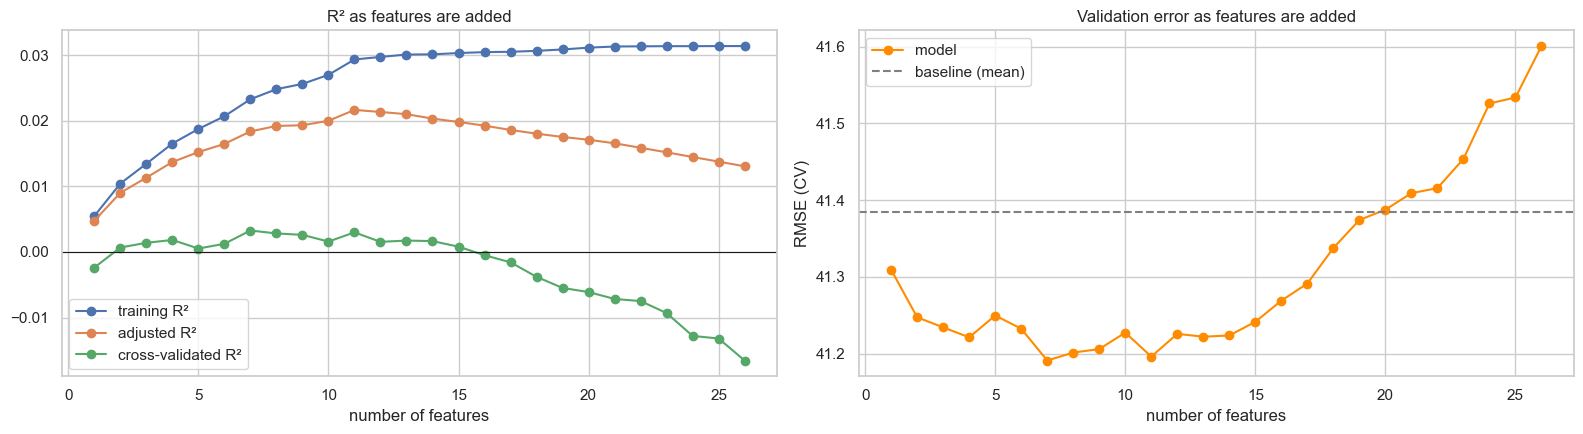

,feature added,r of the feature,R2_train,R2_adjusted,cv_r2,cv_mae,cv_rmse
n,,,,,,,
1,bmi,0.0741,0.0055,0.0048,-0.0024,33.9732,41.3094
2,age,0.0699,0.0104,0.0090,0.0007,33.8505,41.2475
3,smoking,-0.0603,0.0135,0.0113,0.0014,33.8462,41.2344
4,salt_intake,-0.0568,0.0165,0.0137,0.0018,33.7758,41.2214
5,triglycerides,0.0530,0.0188,0.0152,0.0005,33.8280,41.2498
6,physical_activity,0.0496,0.0207,0.0165,0.0012,33.8581,41.2326
7,HbA1c_level,0.0437,0.0233,0.0184,0.0033,33.9333,41.1912
8,hdl,-0.0374,0.0248,0.0192,0.0028,33.9264,41.2016
9,crp_level,0.0372,0.0256,0.0193,0.0026,33.9272,41.2061


In [13]:
order = [f for f in r_train.abs().sort_values(ascending=False).index
         if f not in ('age_level', 'bmi_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol')]
rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]
    ols = sm.OLS(y_train, sm.add_constant(X_train[cols].astype(float))).fit()
    cv = cv_scores(cols)
    rows.append({'n': k, 'feature added': cols[-1], 'r of the feature': r_train[cols[-1]],
                 'R2_train': ols.rsquared, 'R2_adjusted': ols.rsquared_adj,
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
incremental = pd.DataFrame(rows).set_index('n')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(incremental.index, incremental['R2_train'], marker='o', label='training R²')
axes[0].plot(incremental.index, incremental['R2_adjusted'], marker='o', label='adjusted R²')
axes[0].plot(incremental.index, incremental['cv_r2'], marker='o', label='cross-validated R²')
axes[0].axhline(0, color='k', lw=.8); axes[0].set_xlabel('number of features'); axes[0].legend()
axes[0].set_title('R² as features are added')
axes[1].plot(incremental.index, incremental['cv_rmse'], marker='o', color='darkorange', label='model')
axes[1].axhline(baseline_cv['cv_rmse'], color='grey', ls='--', label='baseline (mean)')
axes[1].set_xlabel('number of features'); axes[1].set_ylabel('RMSE (CV)'); axes[1].legend()
axes[1].set_title('Validation error as features are added')
plt.tight_layout(); plt.show()
incremental.head(12)

**Step-by-step conclusions:**

| Step | What happens | Why |
|---|---|---|
| **1 → 2** (`bmi` + `age`) | The CV R² goes from −0.002 to **0.001** (the first positive value) and the RMSE drops from 41.31 to 41.25. **It is the largest gain of the whole construction.** | `age` is the 2nd most correlated feature with the target (r = 0.070) and is **independent** of `bmi` (correlation −0.007). It therefore brings new information: the contributions add up (training R² 0.0055 + 0.0049 ≈ 0.0104). |
| **2 → 4** (+ `smoking`, + `salt_intake`) | Small improvements: RMSE 41.23 → 41.22. | Features with r ≈ −0.06, also independent of the previous ones. Each adds ~0.3% of training R². |
| **5** (+ `triglycerides`) | The CV RMSE **rises** (41.25). | The feature helps on the training set, but does not generalize: the contribution it makes in training is partly noise. |
| **7** (+ `HbA1c_level`) | **Best CV RMSE: 41.191.** | `HbA1c_level` has a low r on the training set (0.044), but combined with the others it improves validation. |
| **8 → 12** | The CV RMSE oscillates between 41.20 and 41.23, without improving. | The new features have r < 0.04: they are at the level of noise (section 2.3). |

**The general pattern (chart):**
- the **training R² always rises** (0.0055 → 0.0298 with 12 features), because each feature gives the model more
  freedom to fit the training data, even if it is noise;
- the **adjusted R²** rises more and more slowly, because it penalizes the number of features;
- the **CV R² stabilizes around 0.002–0.003** from 4 features onwards and then oscillates. The CV RMSE never
  drops more than ~0.2 below the baseline.

**Justification:** the growing gap between the training R² and the CV R² is the definition of *overfitting*. The
first features (`bmi`, `age`) bring real information; the following ones bring mostly noise, which improves the
training fit but not new data.

### 3.3 All combinations of 2 and of 3 features

The incremental construction followed a fixed order (that of |r|), but it may happen that two individually weak
features work well together. To confirm, we test **all** combinations of 2 and of 3 features among the 12 best
continuous/ordinal features (66 pairs and 220 triples), evaluated by cross-validation.

We show the 5 best and the 3 worst of each size, to understand **what distinguishes a good combination from a
bad one.**

In [14]:
pool = order[:12]
combo_rows = []
for size in (2, 3):
    for cols in combinations(pool, size):
        cv = cv_scores(list(cols))
        combo_rows.append({'n': size, 'features': ' + '.join(cols), 'cv_r2': cv['cv_r2'],
                           'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
combos_df = pd.DataFrame(combo_rows)
for size in (2, 3):
    sub = combos_df[combos_df.n == size].sort_values('cv_rmse')
    print(f'\n=== {size} features: {len(sub)} combinations | {(sub.cv_rmse < baseline_cv["cv_rmse"]).sum()} better than the baseline ===')
    display(pd.concat([sub.head(5), sub.tail(3)]).set_index('features'))
print(f'corr(bmi, age) on the training set = {X_train.bmi.corr(X_train.age):.3f}')


=== 2 features: 66 combinations | 53 better than the baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age,2,0.0007,33.8505,41.2475
bmi + HbA1c_level,2,-0.0008,34.0375,41.2767
age + HbA1c_level,2,-0.0009,33.8854,41.2838
bmi + physical_activity,2,-0.0014,34.0030,41.2866
bmi + smoking,2,-0.0012,33.9500,41.2876
alcohol_intake + family_history,2,-0.0070,33.9994,41.4069
hdl + family_history,2,-0.0073,33.9676,41.4131
hdl + alcohol_intake,2,-0.0073,33.9550,41.4162



=== 3 features: 220 combinations | 188 better than the baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age + HbA1c_level,3,0.0026,33.9074,41.2080
bmi + age + blood_pressure,3,0.0022,33.8227,41.2136
bmi + age + smoking,3,0.0014,33.8462,41.2344
bmi + age + physical_activity,3,0.0011,33.8761,41.2360
bmi + age + salt_intake,3,0.0010,33.7757,41.2369
triglycerides + hdl + alcohol_intake,3,-0.0075,34.0138,41.4196
triglycerides + hdl + family_history,3,-0.0078,34.0234,41.4255
hdl + alcohol_intake + family_history,3,-0.0080,33.9871,41.4295


corr(bmi, age) on the training set = -0.007


**Conclusions:**
- **Best pair: `bmi` + `age`** (CV RMSE 41.248). **Best triple: `bmi` + `age` + `HbA1c_level`** (41.208),
  followed by `bmi` + `age` + `blood_pressure` (41.214).
- **The 5 best pairs and the 5 best triples all contain `bmi`**, and all the best triples contain `bmi` and
  `age`.
- **The worst combinations** put together `hdl`, `alcohol_intake`, `family_history` and `triglycerides` (RMSE ≈
  41.41–41.43, **worse than the baseline**).
- Even so, 53 of the 66 pairs and 188 of the 220 triples end up (very slightly) below the baseline.

**Justification — why do some combinations give less error than others?**
1. **A combination is only as good as the features that make it up.** `bmi` and `age` are the two features with
   the highest |r| and the only ones clearly above the noise in 2.3. Any combination without them loses.
2. **The features must bring different information.** `bmi` and `age` have a correlation of −0.007 with each
   other: each explains a different part of the target's variance, and the effects add up. Putting together two
   correlated features (such as `bmi` and `bmi_level`) adds nothing, because they repeat the same information.
3. **Adding features unrelated to the target makes the model worse.** The worst combinations are made up of
   features at the level of noise. The model estimates coefficients for them from random patterns in the training
   data, which do not repeat in the validation data, and the error goes up.

The exhaustive search confirms the order of the incremental construction: there is no "hidden" pair or triple
that works better than the combinations with `bmi` and `age`.

### 3.4 Clinical groups of features

Another way to choose combinations is to use **domain knowledge**: grouping the features by the type of clinical
information they represent and seeing whether any group, as a whole, explains the target. If the target were, for
example, a lipid marker, the lipid group should stand out.

In [15]:
GROUPS = {
    'Anthropometric (age, bmi)':              ['age', 'bmi'],
    'Anthropometric + glycaemic':             ['age', 'bmi', 'HbA1c_level'],
    'Glycaemic (HbA1c)':                      ['HbA1c_level'],
    'Lipid':                                  ['cholesterol', 'triglycerides', 'hdl', 'ldl'],
    'Blood pressure / cardiac':               ['systolic_bp', 'diastolic_bp', 'blood_pressure', 'heart_rate'],
    'Inflammatory':                           ['crp_level', 'homocysteine_level', 'plasma_value'],
    'Lifestyle':                              ['smoking', 'physical_activity', 'stress_level', 'sugar_consumption',
                                               'sleep_hours', 'alcohol_intake', 'salt_intake'],
    'Sociodemographic':                       ['gender', 'education_level', 'family_history',
                                               'employment_status_Retired', 'employment_status_Unemployed'],
    'All continuous numeric':                 CONTINUOUS,
}
groups = pd.DataFrame({g: {'n_features': len(c), **cv_scores(c)} for g, c in GROUPS.items()}).T
groups['better than baseline?'] = groups['cv_rmse'] < baseline_cv['cv_rmse']
groups.sort_values('cv_rmse')

,n_features,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse,better than baseline?
Anthropometric + glycaemic,3.0000,0.0131,0.0026,0.0091,33.9074,41.2080,True
"Anthropometric (age, bmi)",2.0000,0.0108,0.0007,0.0096,33.8505,41.2475,True
Glycaemic (HbA1c),1.0000,0.0020,-0.0043,0.0043,34.0091,41.3526,True
All continuous numeric,17.0000,0.0291,-0.0056,0.0174,33.9903,41.3733,True
Lifestyle,7.0000,0.0121,-0.0071,0.0135,33.9405,41.4047,False
Lipid,4.0000,0.0058,-0.0073,0.0126,33.9931,41.4164,False
Inflammatory,3.0000,0.0018,-0.0085,0.0073,33.9810,41.4390,False
Blood pressure / cardiac,4.0000,0.0020,-0.0105,0.0058,34.0077,41.4768,False
Sociodemographic,5.0000,0.0025,-0.0135,0.0045,34.0732,41.5417,False


**Conclusions:**
- Only **4 groups** end up below the baseline: **anthropometric + glycaemic** (RMSE 41.208), anthropometric
  (41.248), glycaemic (41.353) and, by very little, all the continuous numeric features (41.373 against 41.385).
- The **lipid, blood pressure, inflammatory, lifestyle and sociodemographic groups all end up above the
  baseline**: they predict worse than the mean.
- The group with **all 17 continuous numeric features** has the highest training R² (0.029), but in
  cross-validation it ends up practically equal to the baseline (41.373 against 41.385). The little signal from
  `age` and `bmi` is almost entirely cancelled out by the noise of the other 15 features.

**Justification:** a group works if it contains features related to the target. The winning groups are the ones
that include `age` and `bmi`, the only ones with real signal. The other groups are made up of features with
r ≈ 0 (EDA, section 3.4) and, with nothing to learn, they only add noise.

The poor performance of the lipid group is informative: **there is no evidence that the target is a lipid
marker**, because cholesterol, triglycerides, HDL and LDL do not explain it. The same goes for blood pressure and
inflammation. The name and units of the target remain unknown.

### 3.5 What if we use all the features? *Overfitting*

The natural temptation is to "put everything into the model". We fit the regression with the 30 features and
compare the performance on the **training set** with the performance in **cross-validation**. A large gap between
the two is the classic sign of ***overfitting***: the model fits the noise specific to the training data, which
does not repeat on new data.

In [16]:
ols_all = sm.OLS(y_train, sm.add_constant(X_train.astype(float))).fit()
cv_all = cv_scores(FEATURES)
print(f'Training R2 = {ols_all.rsquared:.4f} | adjusted R2 = {ols_all.rsquared_adj:.4f} | '
      f'F test: F = {ols_all.fvalue:.2f}, p = {ols_all.f_pvalue:.4f}')
print(f'CV: R2 = {cv_all["cv_r2"]:.4f} | MAE = {cv_all["cv_mae"]:.3f} | RMSE = {cv_all["cv_rmse"]:.3f}')
print(f'Baseline CV RMSE = {baseline_cv["cv_rmse"]:.3f}')
sig = ols_all.pvalues.drop('const')
print(f'\nCoefficients with p < 0.05: {list(sig[sig < 0.05].index)}')

Training R2 = 0.0370 | adjusted R2 = 0.0159 | F test: F = 1.75, p = 0.0073
CV: R2 = -0.0261 | MAE = 34.201 | RMSE = 41.793
Baseline CV RMSE = 41.385

Coefficients with p < 0.05: ['bmi_level', 'bmi', 'triglycerides', 'salt_intake']


**Conclusions:** with the 30 features:
- the **training R² is the highest of all (0.0370)** and the *F* test is significant (p = 0.007);
- but the **CV R² is −0.026** and the CV RMSE is **41.79, clearly worse than the baseline (41.38)**;
- the adjusted R² (0.0159) is lower than that of models with fewer features (section 3.2);
- 4 coefficients are significant: `bmi_level`, `bmi`, `triglycerides` and `salt_intake`. Two of them are the
  collinear pair `bmi`/`bmi_level`, whose coefficients come out distorted (see 3.6).

**Justification:** this is ***overfitting***. With 30 coefficients to estimate and almost no real signal, the
model uses its flexibility to fit random patterns in the training data. Those patterns do not exist in the
validation data, so **the model with the most features is the one that generalizes worst**.

It is also a good example that a significant *F* test does not guarantee a useful model: the test says that at
least one coefficient differs from zero, not that the model predicts well.

### 3.6 The effect of collinearity on the coefficients

To show in practice the problem identified in 3.1, we compare the coefficient of `bmi` in two models:
- with `bmi` only;
- with `bmi` **and** `bmi_level` (its discretized version, VIF ≈ 8).

If collinearity is a problem, the standard error of the coefficient increases and the p-value gets worse,
**without the model predicting any better**.

In [17]:
m1 = sm.OLS(y_train, sm.add_constant(X_train[['bmi']])).fit()
m2 = sm.OLS(y_train, sm.add_constant(X_train[['bmi', 'bmi_level']])).fit()
colin = pd.DataFrame({
    'bmi only':          {'bmi coef': m1.params['bmi'], 'bmi std. error': m1.bse['bmi'], 'bmi p-value': m1.pvalues['bmi'],
                          'training R2': m1.rsquared, 'CV RMSE': cv_scores(['bmi'])['cv_rmse']},
    'bmi + bmi_level':   {'bmi coef': m2.params['bmi'], 'bmi std. error': m2.bse['bmi'], 'bmi p-value': m2.pvalues['bmi'],
                          'training R2': m2.rsquared, 'CV RMSE': cv_scores(['bmi', 'bmi_level'])['cv_rmse']},
}).T
colin

,bmi coef,bmi std. error,bmi p-value,training R2,CV RMSE
bmi only,0.4254,0.1531,0.0055,0.0055,41.3094
bmi + bmi_level,1.2453,0.4343,0.0042,0.0084,41.3448


**Conclusions:**
- **`bmi` only:** coefficient 0.425, standard error 0.153.
- **`bmi` + `bmi_level`:** the coefficient of `bmi` **almost triples** (1.245) and so does the standard error
  (0.434). The training R² rises slightly (0.0055 → 0.0084), but the **CV RMSE gets worse** (41.31 → 41.34).

**Justification:** since `bmi` and `bmi_level` measure the same thing (correlation 0.936), the model cannot
separate the effect of each. The coefficient of `bmi` stops meaning "effect of one unit of BMI", because it is
now offset by the coefficient of `bmi_level` in the opposite direction. The coefficients become **unstable and
inflated**, with no gain in prediction. This confirms the decision to use only the continuous variables.

### 3.7 Variants: target transformation and polynomial terms

We test two ideas, applied to the best combination found so far:
1. **`log1p(target)`**: reduces the skew of the target. The metrics are computed back on the original scale, so
   that they are comparable;
2. **Degree-2 polynomial**: adds the squares and the products between features (interactions).

In [18]:
best_combo_row = combos_df.sort_values('cv_rmse').iloc[0]
best_inc_n = incremental['cv_rmse'].idxmin()
candidates_multi = {
    f'Incremental (best n = {best_inc_n})': order[:best_inc_n],
    f'Best combination ({best_combo_row.features})': best_combo_row.features.split(' + '),
}
BEST_MULTI_NAME = min(candidates_multi, key=lambda k: cv_scores(candidates_multi[k])['cv_rmse'])
BEST_MULTI = candidates_multi[BEST_MULTI_NAME]
print('Candidates:'); [print(f'  {k}: {v}') for k, v in candidates_multi.items()]
print(f'Basis for the variants: {BEST_MULTI_NAME}\n')

variants = pd.DataFrame({
    'linear':                cv_scores(BEST_MULTI),
    'log1p(target)':         cv_scores(BEST_MULTI, log_target=True),
    'degree-2 polynomial':   cv_scores(BEST_MULTI, degree=2),
}).T
print(f'skew of the target: {y_train.skew():.2f} -> skew of log1p(target): {np.log1p(y_train).skew():.2f}')
variants

Candidates:
  Incremental (best n = 7): ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']
  Best combination (bmi + age + HbA1c_level): ['bmi', 'age', 'HbA1c_level']
Basis for the variants: Incremental (best n = 7)

skew of the target: 0.53 -> skew of log1p(target): -0.16


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
linear,0.0248,0.0033,0.0105,33.9333,41.1912
log1p(target),0.0033,-0.0176,0.0291,33.9824,41.6151
degree-2 polynomial,0.0768,0.0117,0.0221,34.0876,41.0132


**Conclusions:** the two candidates for the multiple model were:
- **incremental with 7 features** (CV RMSE 41.191);
- **the best triple** `bmi` + `age` + `HbA1c_level` (41.208).

The 7-feature one has the lowest error and was used as the basis for the variants:
- **`log1p(target)`:** it reduces the skew of the target (0.53 → −0.16), but **makes the model worse** (CV RMSE
  41.62, CV R² −0.018);
- **degree-2 polynomial:** it raises the CV R² to 0.012 and lowers the RMSE to 41.01, but **makes the MAE worse**
  (34.09 vs 33.93). With 7 features, it goes from 7 to 35 terms and the training R² triples (0.077): a sign of
  *overfitting*.

**Justification:**
- In the Boston Housing example, `log1p` helped because there were strong relationships, which became more linear
  on the logarithmic scale. Here the problem is not the shape of the distribution: it is the lack of information
  in the features. The log compresses the high values, and the model ends up underestimating them even more.
- The gain of the polynomial is smaller than the standard deviation between folds (0.022) and is not confirmed by
  the MAE. It is not robust.

**Decision:** keep the **linear** regression.

### 3.8 Chosen multiple model: statistical analysis and visualization

We analyse the chosen model with `statsmodels`:
- the ***F* test** of the whole model, $H_0: \beta_1 = \dots = \beta_p = 0$, which answers the question (is any
  feature useful?);
- the ***t* test** of each coefficient;
- the same actual-vs-predicted and residual charts used in the simple regression.

Features: ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                93.2643     15.300      6.096      0.000      63.251     123.277
bmi                   0.3983      0.152      2.615      0.009       0.100       0.697
age                   0.1388      0.054      2.580      0.010       0.033       0.244
smoking              -2.4445      1.338     -1.828      0.068      -5.068       0.179
salt_intake          -0.6715      0.314     -2.141      0.032      -1.287      -0.056
triglycerides         0.0343      0.017      2.021      0.043       0.001       0.068
physical_activity     2.1089      1.349      1.563      0.118      -0.538       4.756
HbA1c_level           3.7061      1.927      1.923      0.055      -0.075       7.487

Training R2 = 0.0233 | adjusted R2

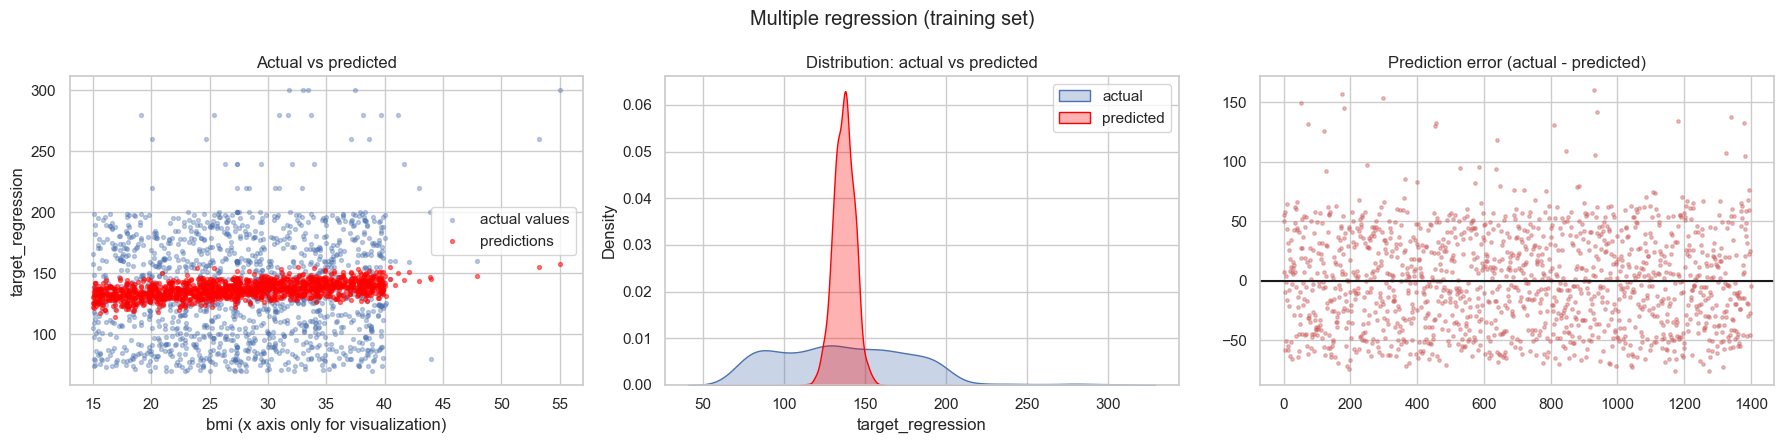

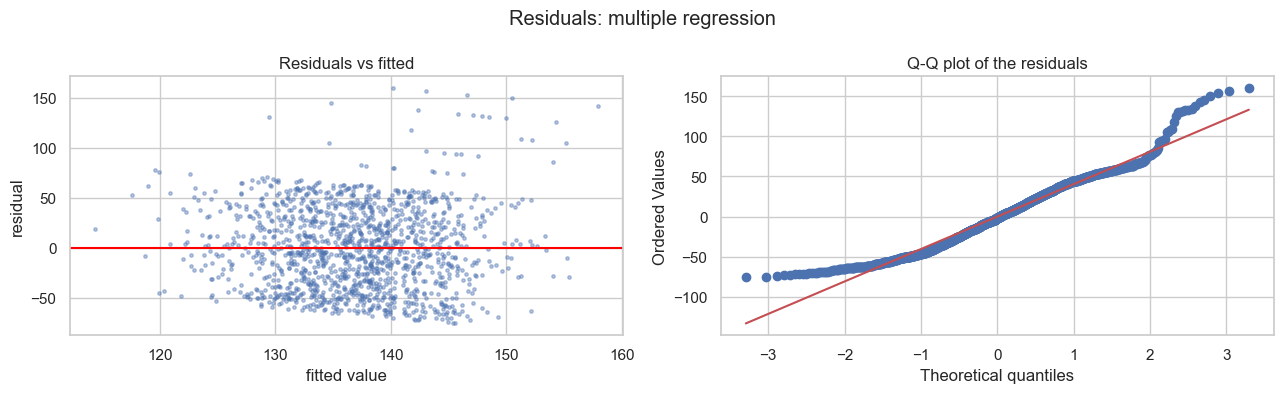

mean of the residuals = 0.000 | skew = 0.43
Predictions: min 114.4, max 157.9, standard deviation 6.32


In [19]:
ols_multi = sm.OLS(y_train, sm.add_constant(X_train[BEST_MULTI].astype(float))).fit()
print(f'Features: {BEST_MULTI}\n')
print(ols_multi.summary().tables[1])
print(f'\nTraining R2 = {ols_multi.rsquared:.4f} | adjusted R2 = {ols_multi.rsquared_adj:.4f}')
print(f'Global F test: F = {ols_multi.fvalue:.3f}, p = {ols_multi.f_pvalue:.2e}')
eq = ' '.join(f'{v:+.3f} x {k}' for k, v in ols_multi.params.drop('const').items())
print(f'\nEquation: target_regression = {ols_multi.params["const"]:.3f} {eq}')

plot_real_vs_pred(X_train['bmi'], y_train, ols_multi.fittedvalues, 'bmi (x axis only for visualization)',
                  'Multiple regression (training set)', line=False)
residual_plots(ols_multi.fittedvalues, ols_multi.resid, 'Residuals: multiple regression')
print(f'Predictions: min {ols_multi.fittedvalues.min():.1f}, max {ols_multi.fittedvalues.max():.1f}, '
      f'standard deviation {ols_multi.fittedvalues.std():.2f}')

**Conclusions — chosen multiple model: incremental construction with 7 features.**

$$\widehat{target} = 93.26 + 0.398\,bmi + 0.139\,age - 2.44\,smoking - 0.672\,salt + 0.034\,trig + 2.11\,phys.act + 3.71\,HbA1c$$

- **Global *F* test:** F = 4.74, p = 2.8×10⁻⁵. We reject $H_0$ (all β = 0): the features, taken together, do have
  a statistical relationship with the target.
- **Significant coefficients (p < 0.05):** `bmi` (+0.40 per unit), `age` (+0.14 per year), `salt_intake` (−0.67)
  and `triglycerides` (+0.034). `HbA1c_level` (p = 0.055) and `smoking` (p = 0.068) sit on the borderline;
  `physical_activity` is not significant (p = 0.12).
- The coefficients of `bmi` (0.398) and `age` (0.139) are practically the same as in the simple models (0.425 and
  0.141). This confirms that the features are independent (VIF ≈ 1): putting them together does not change the
  effect of either.
- **Training R² = 0.023 (adjusted 0.018):** the model explains about **2%** of the variance, 4 times more than the
  simple regression, but still very little.

**Visualization:** the predictions spread a little more than those of the simple model (114–158, standard
deviation 6.3, against 3.1), but they remain very concentrated compared with the actual values (standard
deviation 41.4). The residuals behave the same way: no pattern, positive skew (skew = 0.43).

**Clinical interpretation: caution.** Some signs are not what would be expected clinically (for example, more
salt associated with a *lower* target). Since the effects are minuscule and the target is unknown, **we should
not draw clinical conclusions** from these coefficients.

**Justification for the choice:** it is the combination with the lowest CV RMSE (41.191). As an alternative, the
triple `bmi` + `age` + `HbA1c_level` has an almost identical error (41.208), with less than half the features.
The difference between the two (0.017) is much smaller than the variability between folds, so the triple would be
an equally defensible choice by the principle of parsimony (preferring the simpler model when performance is
equivalent).

### Summary of the Multiple Linear Regression

| Question | Answer | Evidence |
|---|---|---|
| Does combining features help? | **A little, up to ~4–7 features** | CV RMSE 41.31 (1 feature) → 41.19 (7) |
| Which is the best group? | **`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level`** | Lowest CV RMSE among the incremental construction, 286 combinations and 9 clinical groups |
| Why is `bmi` + `age` the best pair? | They are the 2 features with the most signal **and** they are independent of each other | r = 0.074 and 0.070; correlation between them −0.007 |
| And with all the features? | **Worse than the baseline** | *Overfitting*: training R² 0.0370, CV R² −0.026 |
| Use continuous + discretized? | **No** | Unstable and inflated coefficients, with no gain in prediction |
| Does it make sense? | **Yes** | Combining weak, independent features adds up small R² values (0.0055 + 0.0049 + …), but the total stays at ~2% |

## 4. Final evaluation on the test set

With every choice settled **using the training set only**, we now evaluate the models on the test set (600
records never used). It is this evaluation that answers the assignment: *"Evaluate both models using appropriate
metrics (R², MAE, RMSE)"*.

We compare four models:
- the **Baseline** (training mean), the minimum reference;
- the **simple regression** chosen in section 2;
- the **multiple regression** chosen in section 3;
- the **regression with all the features**, only to confirm the *overfitting* (it is not a chosen model).

### 4.1 Metrics on the test set

Each model is trained on the whole training set and evaluated on the test set. We show the training metrics
alongside the test ones: the difference between the two shows how much each model loses when moving to new data.

In [20]:
final_models = {
    'Baseline (mean)':                         ('mean', FEATURES),
    f'Simple ({BEST_SIMPLE})':                  ('linear', [BEST_SIMPLE]),
    f'Multiple ({" + ".join(BEST_MULTI)})':     ('linear', BEST_MULTI),
    f'All features ({len(FEATURES)})':          ('linear', FEATURES),
}
preds, rows = {}, {}
for name, (kind, cols) in final_models.items():
    predict = predict_mean(y_train) if kind == 'mean' else fit_linear(X_train[cols], y_train)
    preds[name] = predict(X_test[cols])
    rows[name] = {**{f'train_{k}': v for k, v in metrics(y_train, predict(X_train[cols])).items()},
                  **{f'test_{k}': v for k, v in metrics(y_test, preds[name]).items()}}
results = pd.DataFrame(rows).T
names = list(preds)
results

,train_R2,train_MAE,train_RMSE,test_R2,test_MAE,test_RMSE
Baseline (mean),0.0000,33.9128,41.3560,-0.0058,34.2872,41.0163
Simple (bmi),0.0055,33.9046,41.2423,-0.0024,34.1833,40.9479
Multiple (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),0.0233,33.6568,40.8713,0.0045,34.1100,40.8067
All features (30),0.0370,33.2981,40.5832,-0.0180,34.3145,41.2641


**Conclusions — results on the test set (600 patients never seen):**

| Model | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (mean) | −0.006 | 34.29 | 41.02 |
| Simple (`bmi`) | −0.002 | 34.18 | 40.95 |
| **Multiple (7 features)** | **0.005** | **34.11** | **40.81** |
| All features (30) | −0.018 | 34.31 | 41.26 |

- **The multiple regression is the best on all three metrics**, followed by the simple one and the baseline.
  **The ordering is the same as in cross-validation**: the choices made on the training set alone generalized
  consistently.
- The model with all the features is **the worst**, below the baseline. It has the highest training R² (0.0370)
  and the lowest test R² (−0.018), which confirms the *overfitting* detected in 3.5.
- The improvements are **very small**: the multiple model errs on average by **34.11** against **34.29** for the
  baseline, 0.18 units less (**0.5%**).
- In every model the test R² is lower than the training one, as expected.

### 4.2 Are the differences between models real? (*bootstrap*)

The differences in the previous table may be small. To find out whether they are real or a matter of chance
(of which patients happened to fall into the test set), we use ***bootstrap***: we resample the test set 1000
times, with replacement, and recompute the metrics on each resample. This gives us a **95% confidence interval**
for each metric and for the difference between models.

If the interval of the difference between a model and the baseline includes zero, **we cannot claim that the
model is better than predicting the mean**.

In [21]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))

boot = {}
for name, p in preds.items():
    r2s = [r2_score(yt[i], p[i]) for i in idx]; rm = [rmse(yt[i], p[i]) for i in idx]
    boot[name] = {'R2 95% CI': f'[{np.percentile(r2s, 2.5):.3f}, {np.percentile(r2s, 97.5):.3f}]',
                  'RMSE 95% CI': f'[{np.percentile(rm, 2.5):.2f}, {np.percentile(rm, 97.5):.2f}]'}
for name in names[1:]:
    d = [rmse(yt[i], preds[name][i]) - rmse(yt[i], preds[names[0]][i]) for i in idx]
    boot[name]['RMSE diff. vs baseline (95% CI)'] = f'{np.mean(d):+.3f}  [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]'
pd.DataFrame(boot).T.fillna('—')

,R2 95% CI,RMSE 95% CI,RMSE diff. vs baseline (95% CI)
Baseline (mean),"[-0.026, -0.000]","[38.63, 43.29]",—
Simple (bmi),"[-0.026, 0.011]","[38.60, 43.19]","-0.065 [-0.292, +0.153]"
Multiple (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),"[-0.031, 0.032]","[38.52, 42.96]","-0.194 [-0.742, +0.322]"
All features (30),"[-0.057, 0.013]","[38.91, 43.44]","+0.256 [-0.369, +0.867]"


**Conclusions:**
- The confidence intervals of the RMSE **overlap almost completely**: every model falls between ~38.5 and ~43.5.
- **RMSE difference against the baseline:**
  - simple: −0.065, 95% CI **[−0.29, +0.15]**;
  - multiple: −0.194, 95% CI **[−0.74, +0.32]**;
  - all features: +0.256, 95% CI [−0.37, +0.87].
- **Every interval includes zero.**

**Justification:** since zero lies inside every interval, **we cannot claim, with 95% confidence, that any model
is better than predicting the mean**. The small advantages in table 4.1 may result from which patients happened
to fall into the test set. With a different train/test split, the ordering could change.

### 4.3 Visualizing the comparison

Two kinds of chart:
1. **Bars with R², MAE and RMSE on the test set**, to compare the models directly;
2. **Predicted vs actual values on the test set.** In a perfect model, every point would lie on the red diagonal.
   In a model that learns nothing, the points form a horizontal line at the mean.

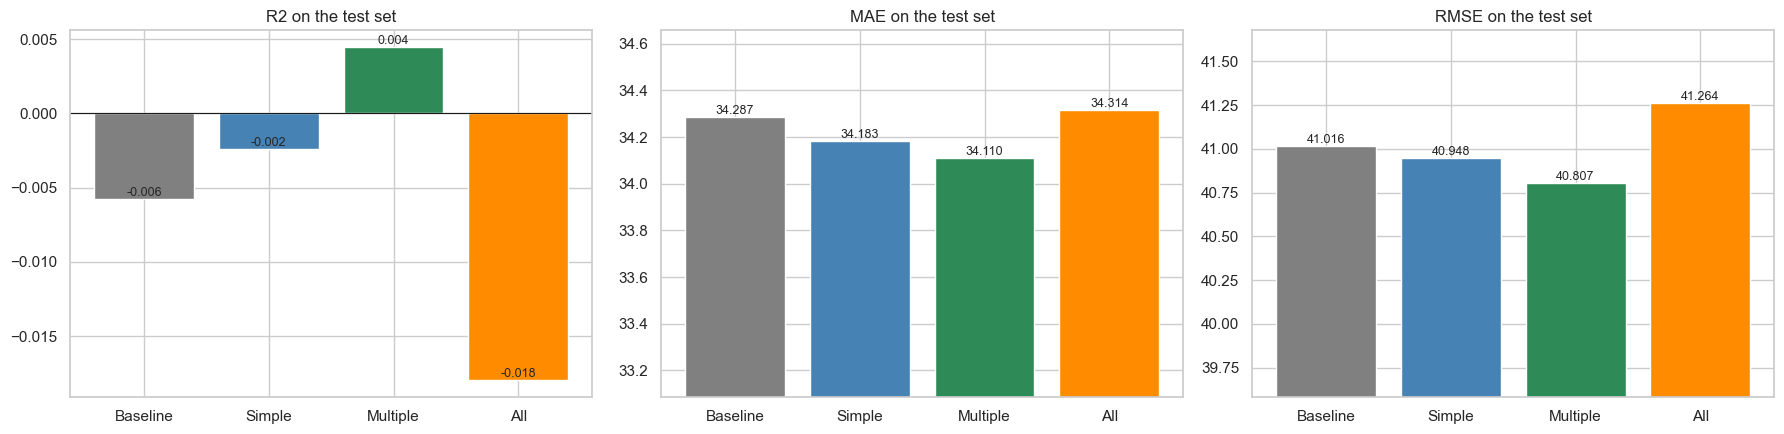

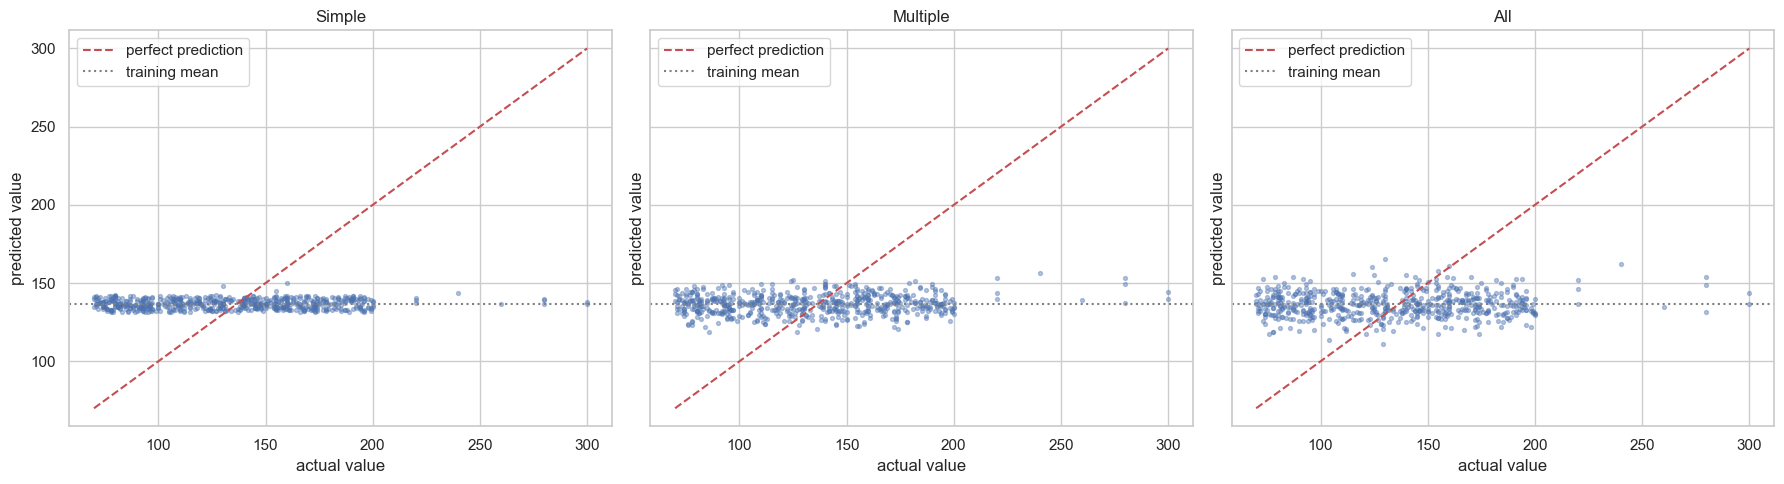

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
short = ['Baseline', 'Simple', 'Multiple', 'All']
for ax, m in zip(axes, ['R2', 'MAE', 'RMSE']):
    vals = results[f'test_{m}'].to_numpy()
    ax.bar(short, vals, color=['grey', 'steelblue', 'seagreen', 'darkorange'])
    ax.set_title(f'{m} on the test set'); ax.axhline(0, color='k', lw=.8)
    for i, v in enumerate(vals): ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    if m != 'R2': ax.set_ylim(vals.min() * 0.97, vals.max() * 1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name, s in zip(axes, names[1:], short[1:]):
    ax.scatter(y_test, preds[name], s=8, alpha=.4)
    lims = [y_test.min(), y_test.max()]; ax.plot(lims, lims, 'r--', label='perfect prediction')
    ax.axhline(y_train.mean(), color='grey', ls=':', label='training mean')
    ax.set_xlabel('actual value'); ax.set_ylabel('predicted value'); ax.set_title(s); ax.legend()
plt.tight_layout(); plt.show()

**Conclusions:**
- **Bars:** the four models have practically identical metrics (MAE between 34.1 and 34.4; RMSE between 40.8 and
  41.3). The scales of the MAE and RMSE charts were zoomed in so that the differences are visible; on a scale
  starting at zero, the bars would be indistinguishable.
- **Predicted vs actual:** instead of following the red diagonal, the predictions form a **horizontal band**
  around the training mean (~137). Patients with target 70 and patients with target 300 get similar predictions.

**Justification:** this is the picture of a model that found no information in the features to tell patients
apart. The multiple model "opens up" the band a little more than the simple one, but it is still far from the
diagonal.

### 4.4 Why does no feature explain the target? A final look at `target_regression`

Before the discussion, we go back to the target itself to understand **where** its variation comes from. The
actual-vs-predicted charts (2.5) suggest that almost every value is spread evenly between 70 and 200, with few
values above. We check:
- whether, between 70 and 200, the distribution is compatible with a **uniform** one (Kolmogorov-Smirnov test);
- how many values lie above 200 and which diagnostic class they belong to (a purely descriptive use of
  `target_class`, as in the EDA; it enters no model).

Values between 70 and 200: 1957 (97.9%) | KS vs uniform(70, 200): D = 0.038, p = 0.00706
Values above 200: 43 | by class: {'DI_HY': 22, 'DI_HT': 21}
Proportion of each class with target > 200: {'DI_HT': 0.247, 'DI_HY': 0.012, 'HT': 0.0}


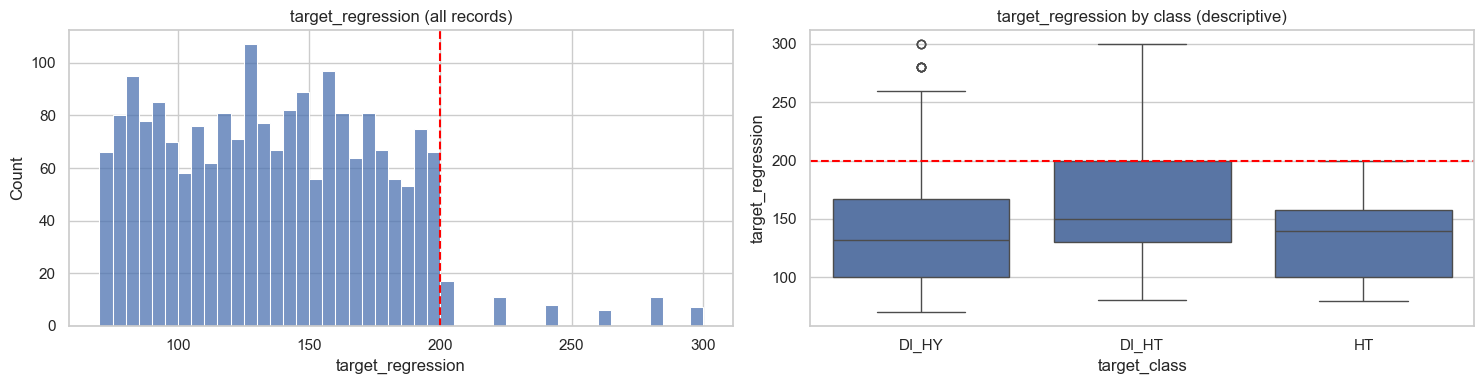

In [23]:
t = raw[TARGET]
inside = t[t <= 200]
ks_u = stats.kstest(inside, stats.uniform(loc=70, scale=130).cdf)
print(f'Values between 70 and 200: {len(inside)} ({len(inside)/len(t):.1%}) | KS vs uniform(70, 200): '
      f'D = {ks_u.statistic:.3f}, p = {ks_u.pvalue:.3g}')
high = raw[t > 200]
print(f'Values above 200: {len(high)} | by class: {high.target_class.value_counts().to_dict()}')
print(f'Proportion of each class with target > 200: '
      f'{(high.target_class.value_counts() / raw.target_class.value_counts()).fillna(0).round(3).to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(t, bins=46, ax=axes[0]); axes[0].axvline(200, color='red', ls='--')
axes[0].set_title('target_regression (all records)')
sns.boxplot(data=raw, x='target_class', y=TARGET, ax=axes[1]); axes[1].axhline(200, color='red', ls='--')
axes[1].set_title('target_regression by class (descriptive)')
plt.tight_layout(); plt.show()

**Conclusions:**
- **97.9%** of the target values lie between 70 and 200, with an **almost uniform** distribution (a flat
  histogram). The KS test rejects perfect uniformity (p = 0.007), but the distance is small (D = 0.038). With
  almost 2000 values, even minimal deviations come out "significant".
- Only **43 values (2.1%) go past 200**, and they concentrate in the `DI_HT` class: **24.7% of the `DI_HT`
  patients** have a target above 200, against 1.2% of `DI_HY` and 0% of `HT`.

**Justification — what this explains:**
1. **A uniform target, unrelated to the features, is the worst-case scenario for a regression.** On a range from
   70 to 200, every value is equally likely for any patient, whatever their BMI, age or cholesterol. There is
   nothing for the model to learn.
2. **What little structure there is comes from the diagnostic class** (high values in `DI_HT`), which we cannot
   use as a predictor. This also explains why the EDA found `target_class` to be the variable most associated
   with the target (η² ≈ 0.027).
3. "Flat" distributions had already been observed in many features in the EDA (section 2.2). It reinforces the
   hypothesis of **synthetic** data, in which the target was generated practically independently of the features.

## 5. Comparison, discussion and conclusions

### 5.1 Comparison of the two models

| | **Simple Linear Regression** | **Multiple Linear Regression** |
|---|---|---|
| Features | `bmi` | `bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level` |
| How they were chosen | Best of 30 features, tested one at a time | Incremental construction, confirmed by 286 combinations and 9 clinical groups |
| Training R² | 0.0055 | 0.0233 |
| Test R² | −0.002 | **0.005** |
| Test MAE | 34.18 | **34.11** |
| Test RMSE | 40.95 | **40.81** |
| RMSE difference against the baseline (95% CI) | −0.07 [−0.29, +0.15] | −0.19 [−0.74, +0.32] |
| Significance | *t*: p = 0.006 | *F*: p = 2.8×10⁻⁵ |

**The multiple regression is slightly better** on all three metrics, in cross-validation and on the test set. By
combining several weak, independent features, it accumulates small contributions: its training R² is 4 times
larger than that of the simple model.

**But neither model is useful in practice.** Both err, on average, by about 34 units, practically the same as
always predicting the mean (34.29). The differences are not statistically robust.

### 5.2 Discussion: does the result make sense?

**Yes, and it was predictable from the EDA.** The chain of reasoning is as follows:

1. **The EDA showed that the best correlation with the target is r ≈ 0.07 (`bmi`).** In simple regression,
   R² = r², so the limit was 0.0055 (0.55%). The model reached exactly that value (sections 2.1 and 2.2).
2. **The features are independent of one another**, so in multiple regression the individual R² values add up
   approximately. Adding the contributions of the ~7 best features (all below 0.6%) gives ~2%, which is the
   result obtained (3.8).
3. **The features that help most are those with the highest |r| and above the noise** (`bmi`, `age`). The ones
   that make the model worse are those which, in the EDA and in the noise test (2.3), cannot be told apart from
   random numbers (`hdl`, `alcohol_intake`, `heart_rate`…).
4. **More features is not better.** With 30 features the model memorizes training noise (*overfitting*) and ends
   up worse than the mean on new data (3.5 and 4.1).
5. **The shape of the model is not the problem.** The residuals show no curvature; polynomials and `log1p` bring
   no robust gains (2.7 and 3.7).
6. **The target itself explains the result.** It is almost uniform between 70 and 200 and only the rare values
   above 200 have any link, to the `DI_HT` class (4.4). There is no structure in the features for the model to
   learn.

**Parallel with the classification:** in the EDA we saw that `target_class` is dominated by `DI_HY` (90%), and a
classifier without good features will tend to predict that class almost always. The equivalent happens here in
regression: **without informative features, the least-squares model converges to the mean** and predicts ~137 for
almost every patient (2.5, 4.3). In both cases, comparing against the *baseline* (majority class / mean) is
mandatory if the model is not to be overrated.

**Statistical significance ≠ predictive power.** Several coefficients have p < 0.05 and the *F* test of the
multiple model is highly significant (p = 2.8×10⁻⁵). With 1400 records, even minuscule effects can be told apart
from zero. The p-value says the effect probably **exists**; the R², the MAE and the RMSE say it is **far too
small** to predict with.

### 5.3 Conclusions
- **Simple regression:** `target_regression = 125.06 + 0.425 × bmi`. `bmi` is the best single feature on every
  criterion, but it explains only 0.55% of the variance.
- **Multiple regression:** 7 features (`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`,
  `physical_activity`, `HbA1c_level`), which explain about 2% of the variance. The triple `bmi` + `age` +
  `HbA1c_level` is an almost equivalent and simpler alternative.
- **Performance on the test set:** R² ≈ 0, MAE ≈ 34, RMSE ≈ 41. **No model predicts better than the mean** in a
  statistically robust way.
- **It is a negative result, but a valid one:** it was obtained with a correct methodology (choices made on the
  training set only, cross-validation, the test set used once, a baseline, a noise control, confidence intervals)
  and it is consistent with the EDA.